## Loading Data

In [ ]:
import pandas as pd

In [ ]:
originaldf = pd.read_csv("data/twitter_sentiment_data.zip", compression="zip")

## Exploratory Analysis and Data Cleaning

In [ ]:
originaldf.head()

,sentiment,message,tweetid
0,-1,@tiniebeany climate change is an interesting h...,792927353886371840
1,1,RT @NatGeoChannel: Watch #BeforeTheFlood right...,793124211518832641
2,1,Fabulous! Leonardo #DiCaprio's film on #climat...,793124402388832256
3,1,RT @Mick_Fanning: Just watched this amazing do...,793124635873275904
4,2,"RT @cnalive: Pranita Biswasi, a Lutheran from ...",793125156185137153


In [ ]:
# for the purpose of my project, what they call sentiment is just stance on climate change
originaldf.rename(columns={'sentiment': 'stance'}, inplace=True)

In [ ]:
f"Before dropping duplicates, there are {len(originaldf)} entries."

'Before dropping duplicates, there are 43943 entries.'

In [ ]:
originaldf = originaldf.drop_duplicates(subset=['message'])

In [ ]:
f"After dropping duplicate tweets, there are {len(originaldf)} entries."

'After dropping duplicate tweets, there are 41033 entries.'

In [ ]:
# there should be 4 different labels:
# -1 is anti climate change, 1 is pro, 2 is news, and 0 is neutral stance.
originaldf['stance'].unique()

array([-1,  1,  2,  0])

In [ ]:
# checking for null stances
originaldf['stance'].isnull().sum()

0

In [ ]:
# checking for null messages
originaldf['message'].isnull().sum()

0

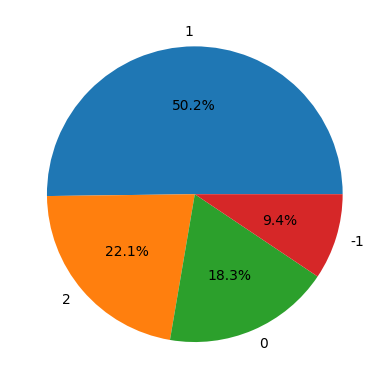

In [ ]:
# to get a general idea of the stance makeup of the data:

import matplotlib.pyplot as plt

counts = originaldf['stance'].value_counts()
plt.pie(counts, labels=counts.index, autopct='%1.1f%%');
plt.show()

As you can see, there is a large amount of pro climate change tweets, and very few anti stance tweets. This is important when considering our stance prediction performance, as it is imbalanced data.

In [ ]:
# since I am not considering news tweets, filtered them out and created a new df
df = originaldf[originaldf['stance'] != 2].copy()
df.reset_index(drop=True, inplace=True)

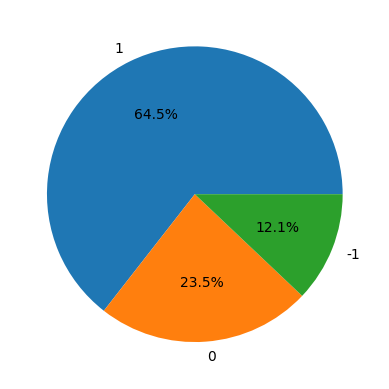

In [ ]:
# examining the sentiment makeup after removing news tweets
counts2 = df['stance'].value_counts()
plt.pie(df['stance'].value_counts(), labels=counts2.index, autopct='%1.1f%%');
plt.show()

When we remove the news tweets, the imbalance becomes even more apparent.

In [ ]:
df['stance'].value_counts()

,count
stance,
1,20599
0,7505
-1,3856


In [ ]:
# how many tweets we are left with once we remove the news tweets
f"After removing news tweets, there are {len(df)} entries."

'After removing news tweets, there are 31960 entries.'

### Preprocessing

Before I apply stance rules and a sentiment model on the data, I will remove items such as usernames, special characters, websites, etc.

In [ ]:
# conversion to lower case
df['message_edit'] = df['message'].str.lower()

In [ ]:
# remove URLs, usernames, # symbol, special characters and numbers
import re
df['message_edit'] = df['message_edit'].apply(lambda x: re.sub(r'https?://\S+|www\.\S+', '', x))
df['message_edit'] = df['message_edit'].apply(lambda x: re.sub(r'@\w+', '', x))
df['message_edit'] = df['message_edit'].apply(lambda x: re.sub(r'#', '', x))
df['message_edit'] = df['message_edit'].apply(lambda x: re.sub(r'\W+', ' ', x))
df['message_edit'] = df['message_edit'].apply(lambda x: re.sub(r'\d+', '', x))

To demonstrate, the before and after of the text cleaning, I have outputted one example below.

In [ ]:
df['message'][1]

'RT @NatGeoChannel: Watch #BeforeTheFlood right here, as @LeoDiCaprio travels the world to tackle climate change https://t.co/LkDehj3tNn httÃ¢â‚¬Â¦'

In [ ]:
df['message_edit'][1]

'rt watch beforetheflood right here as travels the world to tackle climate change httã â â '

## Stance Exploration - My Own Labeling

In the interest of time (since this was not the main focus of my project), I created a simple way to classify tweets' stances by analyzing what the most common words were in each of the categories' tweets.

In [ ]:
# after playing around with the results, some words were in the top n words
# for all categories, so they were not useful to classify stance
# as I went on, I kept adding to my custom stop_words list

from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS
custom_stopwords = ['climate','change','global','warming','rt','amp','man','like','trump','real','just','believe',
                    'people','world','don','think','isn','https','know','new']
combined_stopwords = list(ENGLISH_STOP_WORDS) + custom_stopwords

In [ ]:
from sklearn.feature_extraction.text import CountVectorizer
import numpy as np

In [ ]:
def get_top_n_words(text_category, stopwords, n=10):
  """
  Function that gets the most common n words given a series from a dataframe.

  Arguments:
      - text_category (series): strings to find top-n words from
      - stopwords (list): list of words to remove from consideration
      - n (int): number of words to return, default n = 10

  Returns:
      - top_n_words (list): list of tuples of the form (word, count)

  """
  # to convert the text into a matrix with token counts of each word
  vectorizer = CountVectorizer(stop_words = stopwords)
  X = vectorizer.fit_transform(text_category)
  word_counts = X.sum(axis = 0)
  word_counts = np.asarray(word_counts).flatten()

  # getting the most common words and order them in descending order
  word_list = vectorizer.get_feature_names_out()
  sorted_indices = word_counts.argsort()[::-1]
  top_n_words = [(word_list[i], word_counts[i]) for i in sorted_indices[:n]]
  return top_n_words

In [ ]:
# sorting the edited tweets into categories based on assigned stance
non_cat = df[df['stance'] == -1]['message_edit']
neutral_cat = df[df['stance'] == 0]['message_edit']
bel_cat = df[df['stance'] == 1]['message_edit']

In [ ]:
# finding the top 15 words in each category
most_common_non = get_top_n_words(non_cat, combined_stopwords, 15)
most_common_neutral = get_top_n_words(neutral_cat, combined_stopwords, 15)
most_common_bel = get_top_n_words(bel_cat, combined_stopwords, 15)

In [ ]:
most_common_non

[('science', 196),
 ('obama', 194),
 ('hoax', 174),
 ('weather', 144),
 ('years', 133),
 ('scam', 131),
 ('gore', 124),
 ('data', 119),
 ('scientists', 113),
 ('al', 111),
 ('fake', 108),
 ('liberals', 97),
 ('news', 86),
 ('ice', 85),
 ('caused', 83)]

In [ ]:
most_common_neutral

[('ðÿ', 195),
 ('said', 171),
 ('did', 162),
 ('cause', 142),
 ('hot', 140),
 ('says', 139),
 ('weather', 138),
 ('good', 128),
 ('say', 126),
 ('hoax', 123),
 ('does', 119),
 ('thing', 116),
 ('really', 115),
 ('need', 114),
 ('going', 114)]

In [ ]:
most_common_bel

[('fight', 797),
 ('science', 623),
 ('need', 590),
 ('doesn', 554),
 ('action', 503),
 ('epa', 471),
 ('president', 449),
 ('hoax', 445),
 ('scientists', 435),
 ('time', 422),
 ('stop', 406),
 ('deniers', 401),
 ('earth', 382),
 ('climatechange', 381),
 ('weather', 373)]

In [ ]:
# first created a list of my own words based on common arguments for/against climate change
# then I added words from the top n words above
# if a word was a top n word in more than one category I made one of two choices:
 #    1. If it was generally irrelevant (https, rt) I added it to my stop words list.
 #    2. If it was much more common in one category, I added it to that list.

believer_keywords = ['scientific evidence',
                     'human caused',
                     'scientific consensus',
                     'global warming',
                     'is real',
                     'carbon emissions',
                     'greenhouse gases',
                     'sustainability',
                     'fossil fuels',
                     'carbon footprint',
                     'renewable energy',
                     'act now',
                     'climate crisis',
                     'carbon dioxide',
                     'rising sea levels',
                     'serious',
                     'melting glaciers',
                     'extreme weather',
                     'temperature rise',
                     'climate action',
                     'green new deal',
                     'paris agreement'
                     'eco friendly',
                     'environmental disaster',
                     'environmental impact',
                     'environmental protection',
                     'carbon reduction',
                     'climate refugees',
                     'environmental responsibility',
                     'monsters',
                     'monopoly',
                     'action',
                     'climatechange',
                     'deniers',
                     'doesn',
                     'earth',
                     'epa',
                     'hoax',
                     'need',
                     'president',
                     'science',
                     'scientists',
                     'stop',
                     'time',
                     'weather',
                     'fight']

non_believer_keywords = ['is not real',
                         'natural cycle',
                         'no human impact',
                         'fake news',
                         'manipulation',
                         'natural',
                         'coldest winter',
                         'climate scam',
                         'agenda driven',
                         'weather manipulation',
                         'climate alarmism',
                         'fake',
                         'climate hysterics',
                         'global cooling',
                         'solar activity',
                         'volcanic activity',
                         'sunspots',
                         'natural fluctuation',
                         'weather patterns',
                         'overblown',
                         'global warming pause',
                         'climate conspiracy',
                         'conspiracy',
                         'eco tyranny',
                         'propoganda',
                         'big government',
                         'al',
                         'caused',
                         'data',
                         'gore',
                         'ice',
                         'liberals',
                         'news',
                         'obama',
                         'scam',
                         'years']

neutral_keywords = ['cause',
                    'did',
                    'does',
                    'going',
                    'good',
                    'hot',
                    'really',
                    'said',
                    'say',
                    'says',
                    'thing',
                    'ðÿ']

In [ ]:
def get_stance(message):
  """
  Function that takes a tweet and after searching for believer or non-believer
  or neutral keywords, returns an assigned stance on climate change.

  Arguments:
      - message (string): the tweet to be analyzed

  Returns:
      - string: the assigned stance on climate change (believer, non-believer, neutral)
  """
  believer_found = any(keyword in message for keyword in believer_keywords)
  non_believer_found = any(keyword in message for keyword in non_believer_keywords)
  neutral_found = any(keyword in message for keyword in neutral_keywords)
  if believer_found:
    return 'believer'
  if non_believer_found:
    return 'non-believer'
  if neutral_found:
    return 'neutral'
  else:
    return 'neutral'

In [ ]:
# creating a new stance prediction column in my original dataframe
df['stance_pred'] = df.apply(lambda x: get_stance(x['message_edit'],), axis=1)

In [ ]:
# mapping stances since the original data had integers -1,0,1
def map_stance(stance):
  """
  Function that maps string stances to numbers.
  -1: non-believer
  0: Neutral
  1: believer

  Arguments:
      - sentiment (string): the sentiment to be mapped

  Returns:
      - int: the mapped sentiment
  """
  if stance == 'non-believer':
    return -1                     # anti climate change
  elif stance == 'neutral':
    return 0                      # netural
  else:
    return 1                      # believes in climate change

In [ ]:
df['stance_cat'] = df['stance_pred'].apply(map_stance)

In [ ]:
# my predictions
df['stance_cat'].value_counts()

,count
stance_cat,
1,16395
0,7871
-1,7694


In [ ]:
# original stances
df['stance'].value_counts()

,count
stance,
1,20599
0,7505
-1,3856


Although there is a similar makeup for each stance category, are they classifying the correct tweets as non-believer/neutral/believer?

To evaluate the success of the model, I created a confusion matrix and calculated the accuracy and precision scores.

In [ ]:
from sklearn import metrics

In [ ]:
confusion_matrix = metrics.confusion_matrix(df['stance'], df['stance_cat'])

In [ ]:
matrix = metrics.ConfusionMatrixDisplay(confusion_matrix, display_labels=[-1, 0, 1])

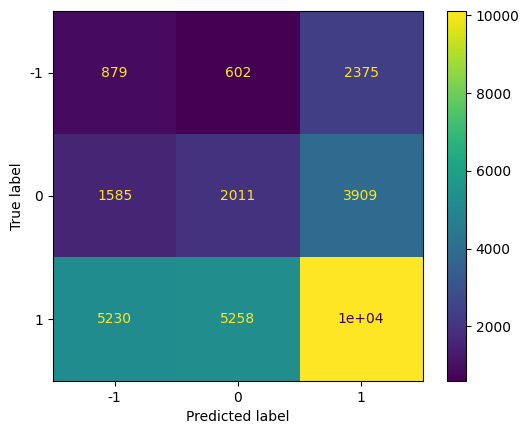

In [ ]:
matrix.plot()
plt.show()

In [ ]:
# accuracy
metrics.accuracy_score(df['stance'], df['stance_cat'])

0.4067897371714643

As you can see, the accuracy was very low for this custom rule-based stance classification. Reasons for this are discussed in my paper. However, as per the confusion matrix above, it was more accurate in predicting the believer tweets. Let's analyze this further.

In [ ]:
# precision
metrics.precision_score(df['stance'], df['stance_cat'], average=None)

array([0.11424487, 0.25549485, 0.61671241])

In [ ]:
np.unique(df['stance'], return_counts=True)

(array([-1,  0,  1]), array([ 3856,  7505, 20599]))

 Even though the rule-based classification accuracy was low (41%), the precision was much higher for believer's tweets (62%). This makes sense since we have so many believer tweets (shown in the pie chart). Considering this, I expected that the classification would be much more successful for believer tweets.

## Sentiment Model

My data already came with labeled stances. Now, I will assign the tweets sentiments so I can then compare the correlation between the two.

In [ ]:
# importing a model to use from hugging face
model = "cardiffnlp/twitter-roberta-base-sentiment-latest"
import os
hf_token = os.environ.get("HUGGING_FACE_TOKEN", "")

For more info on the model, here is the link: [https://huggingface.co/cardiffnlp/twitter-roberta-base-sentiment-latest](https://huggingface.co/cardiffnlp/twitter-roberta-base-sentiment-latest)

I also used an article that demonstrated how to use the model, and the credits to the code in the cell below come from here: [https://huggingface.co/blog/sentiment-analysis-twitter](https://huggingface.co/blog/sentiment-analysis-twitter)

In [ ]:
API_URL = "https://api-inference.huggingface.co/models/" + model
headers = {"Authorization": "Bearer %s" % (hf_token)}

def analysis(data):
  """
  Function to create API call to hugging face for a model, using Inference API.

  Arguments:
      - Data (string): tweet to be analyzed
  """
  payload = dict(inputs=data, options=dict(wait_for_model=True))
  response = requests.post(API_URL, headers=headers, json=payload)
  return response.json()

In [ ]:
import requests

def df_analysis(df):
  """
  Function that performs sentiment analysis on tweets using roberta-base-sentiment hugging face model.

  Arguments:
      - df (pd.dataframe): dataframe with tweets to be analyzed, with column named 'message_edit'

  Returns:
      - processed.df (pd.dataframe): dataframe with tweets and their corresponding predicted sentiment.
  """

  # counter to help track number of tweets processed - used for debugging
  counter = 0

  # to store model's sentiment analysis results
  tweets_analysis = []

  # iterate through each tweet
  for tweet in df['message_edit']:
      counter += 1

      # print count so far every 100 tweets
      if counter % 100 == 0:
        print(f'Tweet count: {counter}/{len(df)}')

      try:
        sentiment_result = analysis(tweet)[0]

        # if the result is not an expected sentiment (positive, neutral, negative) skip it
        if not sentiment_result or not isinstance(sentiment_result, list):
          print(f"Skipping tweet at {counter} due to invalid sentiment result.")
          continue

        # since the model returns the confidence level for each sentiment for each tweet,
        # this extracts only the highest one as the assigned sentiment for the tweet
        init_score = 0
        assigned_label = 'FIRE' # for debugging purposes
        for label_dict in sentiment_result:
          if label_dict['score'] >= init_score:
            init_score = label_dict['score']
            assigned_label = label_dict['label']

        # once the final sentiment is found, add it to the list of results
        tweets_analysis.append({'tweet':tweet, 'sentiment': assigned_label})

      # to see which tweets were not processed
      except Exception as e:
          print(f"Error processing tweet at {counter}: {e}")
          continue

  # add the results to a df to return
  processed_df = pd.DataFrame(tweets_analysis)

  return processed_df

In [ ]:
# apply the model on each tweet on my dataframe
sentiment_df = df_analysis(df)

Streaming output truncated to the last 5000 lines.
Error processing tweet at 27010: 0
Error processing tweet at 27011: 0
Error processing tweet at 27012: 0
Error processing tweet at 27013: 0
Error processing tweet at 27014: 0
Error processing tweet at 27015: 0
Error processing tweet at 27016: 0
Error processing tweet at 27017: 0
Error processing tweet at 27018: 0
Error processing tweet at 27019: 0
Error processing tweet at 27020: 0
Error processing tweet at 27021: 0
Error processing tweet at 27022: 0
Error processing tweet at 27023: 0
Error processing tweet at 27024: 0
Error processing tweet at 27025: 0
Error processing tweet at 27026: 0
Error processing tweet at 27027: 0
Error processing tweet at 27028: 0
Error processing tweet at 27029: 0
Error processing tweet at 27030: 0
Error processing tweet at 27031: 0
Error processing tweet at 27032: 0
Error processing tweet at 27033: 0
Error processing tweet at 27034: 0
Error processing tweet at 27035: 0
Error processing tweet at 27036: 0
Erro

In [ ]:
# saved the results to a csv so I didn't have to run the above code repeatedly
sentiment_df.to_csv('sentiment_df.csv', index=False)

In [ ]:
sentiment_df = pd.read_csv('sentiment_df.csv')

In [ ]:
# results from above model run
sentiment_df

,tweet,sentiment
0,climate change is an interesting hustle as it...,neutral
1,rt watch beforetheflood right here as travels ...,neutral
2,fabulous leonardo dicaprio s film on climate c...,positive
3,rt just watched this amazing documentary by le...,positive
4,unamshow awache kujinga na iko global warming,neutral
...,...,...
19656,global warming,neutral
19657,rt fortunately for rupert murdoch climate chan...,neutral
19658,rt a bit of karma for the man who made the eng...,negative
19659,rt reporter with these extreme temperatures fi...,neutral


In [ ]:
# how many tweets do we have
f"Before removing duplicate tweets, there are {len(sentiment_df)} entries."

'Before removing duplicate tweets, there are 19661 entries.'

In [ ]:
# removing duplicates as I noticed some tweets were present twice
sentiment_df.drop_duplicates(subset = 'tweet', inplace = True)

In [ ]:
# how many tweets we are left with once we remove the duplicate tweets
f"After removing duplicate tweets, there are {len(sentiment_df)} entries."

'After removing duplicate tweets, there are 19031 entries.'

In [ ]:
# examples of what a tweet from each sentiment looks like
pd.set_option('display.max_colwidth', None)
display(sentiment_df[sentiment_df["sentiment"] == 'positive'].head(3))
display(sentiment_df[sentiment_df["sentiment"] == 'neutral'].head(3))
display(sentiment_df[sentiment_df["sentiment"] == 'negative'].head(3))

,tweet,sentiment
2,fabulous leonardo dicaprio s film on climate change is brilliant do watch via,positive
3,rt just watched this amazing documentary by leonardodicaprio on climate change we all think thisã â â,positive
32,nicely said financiers are not philanthropists but allies in the fight against climate change in french,positive


,tweet,sentiment
0,climate change is an interesting hustle as it was global warming but the planet stopped warming for yes while the suv boom,neutral
1,rt watch beforetheflood right here as travels the world to tackle climate change httã â â,neutral
4,unamshow awache kujinga na iko global warming,neutral


,tweet,sentiment
8,bangladesh did not cause climate change so the country does not need ã â å aidã â ï instead it needs compensation for theã â â,negative
10,rt the problem with global warmingã â â and the reason it continues to resist illustration even as the streets flood and hã â â,negative
14,arseholes couldn t predict tomorrows weather in a month heat wave yet we trust them on climate change narrr,negative


In [ ]:
# merging my predictions with the original dataframe so I can explore correlations
merged_df = pd.merge(df, sentiment_df, left_on='message_edit', right_on='tweet', how='inner')

In [ ]:
merged_df

,stance,message,tweetid,message_edit,stance_pred,stance_cat,tweet,sentiment
0,-1,@tiniebeany climate change is an interesting hustle as it was global warming but the planet stopped warming for 15 yes while the suv boom,792927353886371840,climate change is an interesting hustle as it was global warming but the planet stopped warming for yes while the suv boom,believer,1,climate change is an interesting hustle as it was global warming but the planet stopped warming for yes while the suv boom,neutral
1,1,"RT @NatGeoChannel: Watch #BeforeTheFlood right here, as @LeoDiCaprio travels the world to tackle climate change https://t.co/LkDehj3tNn httÃ¢â‚¬Â¦",793124211518832641,rt watch beforetheflood right here as travels the world to tackle climate change httã â â,neutral,0,rt watch beforetheflood right here as travels the world to tackle climate change httã â â,neutral
2,1,Fabulous! Leonardo #DiCaprio's film on #climate change is brilliant!!! Do watch. https://t.co/7rV6BrmxjW via @youtube,793124402388832256,fabulous leonardo dicaprio s film on climate change is brilliant do watch via,neutral,0,fabulous leonardo dicaprio s film on climate change is brilliant do watch via,positive
3,1,RT @Mick_Fanning: Just watched this amazing documentary by leonardodicaprio on climate change. We all think thisÃ¢â‚¬Â¦ https://t.co/kNSTE8K8im,793124635873275904,rt just watched this amazing documentary by leonardodicaprio on climate change we all think thisã â â,non-believer,-1,rt just watched this amazing documentary by leonardodicaprio on climate change we all think thisã â â,positive
4,0,Unamshow awache kujinga na iko global warming https://t.co/mhIflU7M1X,793125429418815489,unamshow awache kujinga na iko global warming,believer,1,unamshow awache kujinga na iko global warming,neutral
...,...,...,...,...,...,...,...,...
19730,1,RT @iansomerhalder: Worried a presidential candidate thinks climate change is a hoax? You should #ProbablyVote @paulwesley…,780882994642944000,rt worried a presidential candidate thinks climate change is a hoax you should probablyvote,believer,1,rt worried a presidential candidate thinks climate change is a hoax you should probablyvote,negative
19731,1,I support the fight to prevent climate change disaster. Will you join us? https://t.co/y3IwJTvxlC via @nextgenclimate,782700322510675968,i support the fight to prevent climate change disaster will you join us via,believer,1,i support the fight to prevent climate change disaster will you join us via,neutral
19732,1,RT @TomthunkitsMind: Climate Change Is Real. https://t.co/a70b3PwrTL,788199197258375168,rt climate change is real,believer,1,rt climate change is real,neutral
19733,0,Do you know that how #climate change can effect your surroundings ? https://t.co/8hpmDRLYQA,788553730043949056,do you know that how climate change can effect your surroundings,neutral,0,do you know that how climate change can effect your surroundings,neutral


In [ ]:
# how many tweets are there in the merged df
f"Before removing duplicate tweets, there are {len(merged_df)} entries."

'Before removing duplicate tweets, there are 19735 entries.'

In [ ]:
merged_df.drop_duplicates(subset = 'tweet', inplace = True)

In [ ]:
# how many tweets we are left with once we remove the duplicate tweets
f"After removing duplicate tweets, there are {len(merged_df)} entries."

'After removing duplicate tweets, there are 19031 entries.'

## Correlation - Stance and Sentiment

Hypothesis: My project puts forward the hypothesis that climate change tweets of positive sentiment tend to correlate with a “believer” stance, whereas negative climate change tweets are related to a “nonbeliever” stance.

Before I explore this, I made some exploratory graphs as a reminder of the stance and sentiment makeup of the data.

In [ ]:
import seaborn as sns

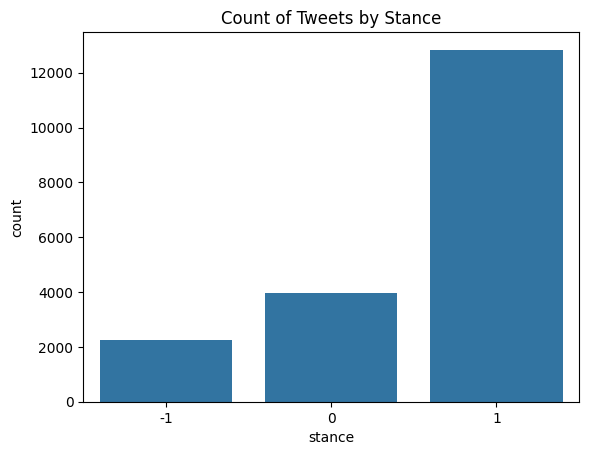

In [ ]:
sns.countplot(x = 'stance', data = merged_df).set_title('Count of Tweets by Stance')
plt.show()

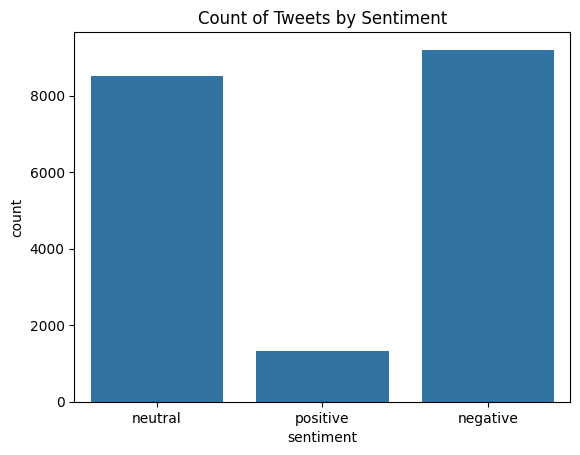

In [ ]:
sns.countplot(x = 'sentiment', data = merged_df).set_title('Count of Tweets by Sentiment')
plt.show()

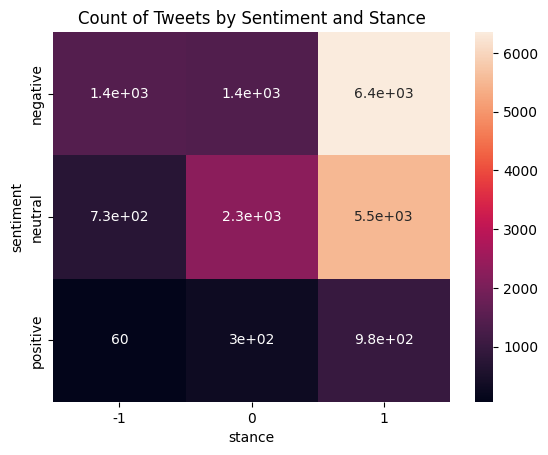

In [ ]:
sns.heatmap(merged_df.pivot_table(index='sentiment', columns='stance', values='tweet', aggfunc='count'), annot=True).set_title('Count of Tweets by Sentiment and Stance')
plt.show()

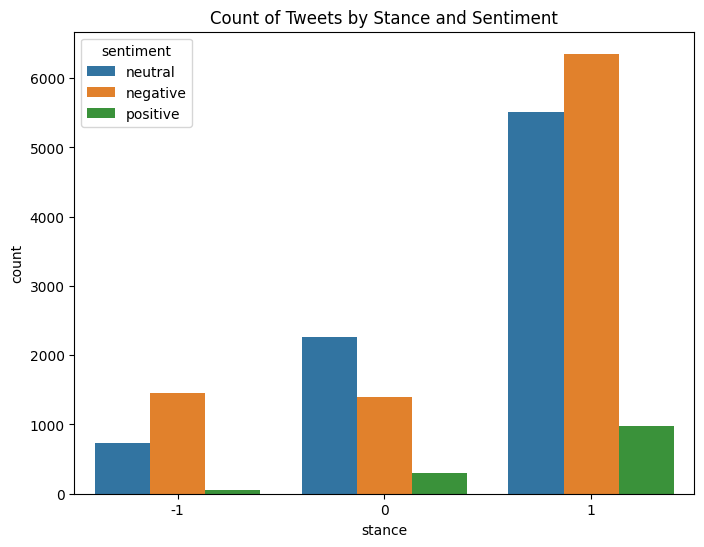

In [ ]:
plt.figure(figsize=(8, 6))
sns.countplot(x = 'stance', hue ='sentiment', data = merged_df).set_title('Count of Tweets by Stance and Sentiment')
plt.show()

Since there are two categorical variables, I calculated the chi-squared value and p-value to assess correlation.

In [ ]:
from scipy import stats

In [ ]:
contingency_table = pd.crosstab(merged_df['sentiment'], merged_df['stance'])

In [ ]:
contingency_table

stance,-1,0,1
sentiment,,,
negative,1448,1396,6354
neutral,729,2261,5509
positive,60,298,976


In [ ]:
data = pd.crosstab(merged_df['stance'], merged_df['sentiment'], margins = False)
stats.chi2_contingency(data)

Chi2ContingencyResult(statistic=555.1641867958244, pvalue=7.808754328514084e-119, dof=4, expected_freq=array([[1081.17944406,  999.01544848,  156.80510746],
       [1911.51752404, 1766.25216752,  277.23030844],
       [6205.3030319 , 5733.73238401,  899.9645841 ]]))

The Chi-square value is around 555. The p-value is around 7.80e-119. Since this is below the typical threshold of 0.05, these calculations indicate there is a relationship between the stance of a tweet (believer, neutral, non-believer) and the tweet sentiment (positive, neutral, negative).

To determine the relationship, I conducted pairwise Chi-square tests.

In [ ]:
# performing pairwise tests below to see where the significance is attributed to
from itertools import combinations
from statsmodels.stats.multitest import multipletests

sentiments = contingency_table.index
stances = contingency_table.columns

pairwise_results = []

# iterate over combinations of sentiments and stances to isolate categories
for senti_pair in combinations(sentiments, 2):
  for stance_pair in combinations(stances, 2):
    sub = contingency_table.loc[list(senti_pair), list(stance_pair)]
    # for each subset, calculate these chi2 metrics
    chi2, p, dof, expected = stats.chi2_contingency(sub)

    # add them to our df
    pairwise_results.append({
        'sentiment_pair': senti_pair,
        'stance_pair': stance_pair,
        'chi2': chi2,
        'p': p,
        'dof': dof,
        'expected': expected
    })

  pairwise_results_df = pd.DataFrame(pairwise_results)

  # need to correct p-value since we are doing multiple tests
  pairwise_results_df['Corrected P-Value'] = multipletests(pairwise_results_df['p'], method='bonferroni')[1]

In [ ]:
  pairwise_results_df

,sentiment_pair,stance_pair,chi2,p,dof,expected,Corrected P-Value
0,"(negative, neutral)","(-1, 0)",437.553031,3.689814e-97,1,"[[1061.2595131984915, 1782.7404868015085], [1115.7404868015085, 1874.2595131984915]]",3.320832e-96
1,"(negative, neutral)","(-1, 1)",124.457607,6.689311e-29,1,"[[1209.7545584045583, 6592.245441595442], [967.2454415954415, 5270.754558404558]]",6.020380e-28
2,"(negative, neutral)","(0, 1)",264.149508,2.138206e-59,1,"[[1826.1436855670104, 5923.85631443299], [1830.8563144329896, 5939.14368556701]]",1.924385e-58
3,"(negative, positive)","(-1, 0)",147.504431,6.087812e-34,1,"[[1339.3978763272955, 1504.6021236727045], [168.60212367270455, 189.39787632729545]]",5.479031e-33
4,"(negative, positive)","(-1, 1)",104.453230,1.609481e-24,1,"[[1331.2305951572755, 6470.769404842725], [176.7694048427246, 859.2305951572754]]",1.448533e-23
5,"(negative, positive)","(0, 1)",20.402385,6.275155e-06,1,"[[1454.8426418439717, 6295.157358156029], [239.15735815602838, 1034.8426418439717]]",5.647640e-05
6,"(neutral, positive)","(-1, 0)",9.891553,1.660392e-03,1,"[[704.6326164874552, 2285.3673835125446], [84.3673835125448, 273.6326164874552]]",1.494353e-02
7,"(neutral, positive)","(-1, 1)",31.319654,2.188529e-08,1,"[[676.6266153423151, 5561.373384657685], [112.37338465768491, 923.6266153423151]]",1.969676e-07
8,"(neutral, positive)","(0, 1)",17.297792,3.195580e-05,1,"[[2198.5216718266256, 5571.478328173374], [360.4783281733746, 913.5216718266254]]",2.876022e-04


Since all corrected p-values are < 0.05, it is difficult to see where the significance is coming from. However we do see some very large Chi-squared values such as:

Negative,Neutral and -1,0
Negative,Neutral and 0,1

This indicates that these relationships are more differ a lot from what we expected, and the relationship is statistically significant.



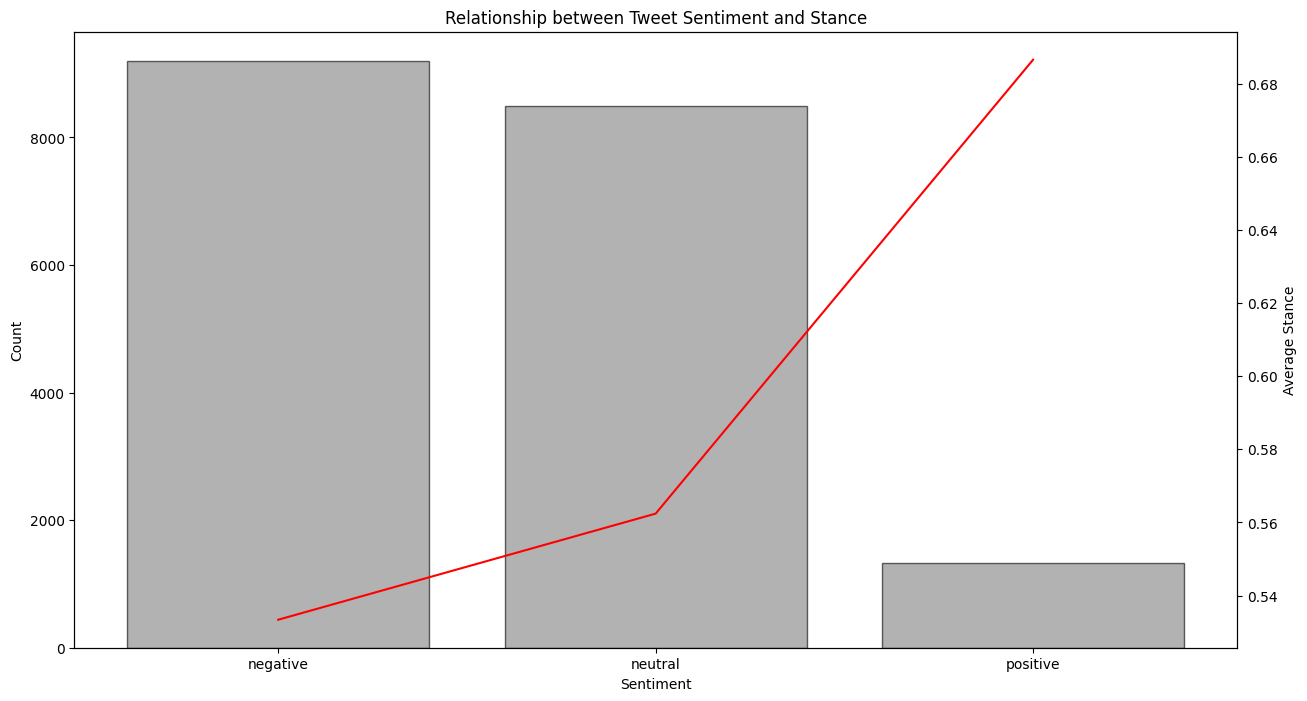

In [ ]:
# below I replicated a graph from one of the studies mentioned in my paper with my data

sentiment_cts = merged_df['sentiment'].value_counts()

mean_stance = merged_df.groupby('sentiment')['stance'].mean()

fig, ax1 = plt.subplots(figsize = (15,8))

# histogram: count (y) vs. sentiment (x)
ax1.bar(sentiment_cts.index, sentiment_cts.values, color = 'grey', edgecolor = 'black', alpha = 0.6, label = 'Count')
ax1.set_xlabel('Sentiment')
ax1.set_ylabel('Count')
ax1.tick_params(axis = 'y', labelcolor = 'black')

# line plot: mean stance (y)
ax2 = ax1.twinx()
ax2.plot(sentiment_cts.index, mean_stance, color = 'red', label = 'Mean Stance')
ax2.set_ylabel('Average Stance')

plt.title('Relationship between Tweet Sentiment and Stance')
plt.show()

As you can see, there is a fairly positive slope when we compare average stance across sentiments. This suggests that there is a correlation between positive tweets and believers, which supports my hypothesis. The negative sentiment tweets seem to have a much lower mean stance (referring to deniers).

## Other data

To test my hypothesis with more than just the above data, I also decided to try it on another dataset that is similar and already has stances and sentiments assigned.

In [ ]:
import kagglehub

In [ ]:
path = kagglehub.dataset_download("deffro/the-climate-change-twitter-dataset")
print("Path to dataset files: ", path)

100%|██████████| 409M/409M [00:08<00:00, 50.3MB/s]

Extracting files...


Path to dataset files:  /root/.cache/kagglehub/datasets/deffro/the-climate-change-twitter-dataset/versions/1


In [ ]:
import os
path = '/root/.cache/kagglehub/datasets/deffro/the-climate-change-twitter-dataset/versions/1'
os.listdir(path)

['disasters.csv', 'The Climate Change Twitter Dataset.csv']

In [ ]:
file_path = os.path.join(path, 'The Climate Change Twitter Dataset.csv')

In [ ]:
df2 = pd.read_csv(file_path)

In [ ]:
df2.head()

,created_at,id,lng,lat,topic,sentiment,stance,gender,temperature_avg,aggressiveness
0,2006-06-06 16:06:42+00:00,6132,NaN,NaN,Weather Extremes,-0.097180,neutral,female,NaN,aggressive
1,2006-07-23 21:52:30+00:00,13275,-73.949582,40.650104,Weather Extremes,0.575777,neutral,undefined,-1.114768,aggressive
2,2006-08-29 01:52:30+00:00,23160,NaN,NaN,Weather Extremes,0.500479,neutral,male,NaN,aggressive
3,2006-11-07 02:46:52+00:00,57868,NaN,NaN,Weather Extremes,0.032816,neutral,male,NaN,aggressive
4,2006-11-27 14:27:43+00:00,304553,NaN,NaN,Importance of Human Intervantion,-0.090428,neutral,male,NaN,aggressive


One difference from the last dataset is that now, sentiments are a continuous variable ranging from -1 to 1 (closer to 1 is positive, closer to -1 is negative). Stance is divided into believers, deniers, and neutral.

In [ ]:
subset = df2[['stance','sentiment']].copy()

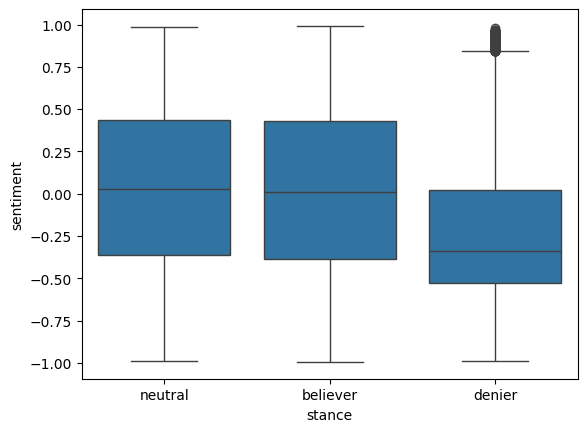

In [ ]:
sns.boxplot(data = subset, x = 'stance', y = 'sentiment')
plt.show()

Upon first glance, it seems like deniers tend to be more negative than believers. Let's explore this further.

Before I perform various tests, I will encode my stance labels in a new column using a similar mapping function to before.

In [ ]:
# mapping sentiments
def map_stance2(stance):
  """
  Function that maps string stances to numbers.
  -1: denier
  0: neutral
  1: believer

  Arguments:
      - sentiment (string): the sentiment to be mapped

  Returns:
      - int: the mapped sentiment
  """
  if stance == 'denier':
    return -1                     # anti climate change
  elif stance == 'neutral':
    return 0                      # netural
  else:
    return 1                     # believes in climate change

In [ ]:
subset['stance_2'] = subset['stance'].apply(map_stance2)

In [ ]:
subset['stance'].value_counts()

,count
stance,
believer,11292424
neutral,3305601
denier,1191386


In [ ]:
subset['stance_2'].value_counts()

,count
stance_2,
1,11292424
0,3305601
-1,1191386


In [ ]:
# tried ANOVA tests (since sentiment is now continous)
anova_result = stats.f_oneway(
    subset[subset['stance_2'] == -1]['sentiment'],
    subset[subset['stance_2'] == 0]['sentiment'],
    subset[subset['stance_2'] == 1]['sentiment']
)

print(f"ANOVA F-value: {anova_result.statistic}")
print(f"ANOVA p-value: {anova_result.pvalue}")

ANOVA F-value: 192605.01397703812
ANOVA p-value: 0.0


The large F-value suggests that there is a high amount of variation between the different stances that indicates it is more than what would just be by chance.

The p-value of 0 allows us to conclude that there is a statistically significant difference in the mean sentiment across the different stances.

In [ ]:
# since sentiment is a continuous variable here, I can use ANOVA tables to see the mean difference
import statsmodels.api as sm
from statsmodels.formula.api import ols
from statsmodels.stats.multicomp import pairwise_tukeyhsd

# fitting the model
model = ols('stance_2 ~ sentiment', data=subset).fit()
anova_table = sm.stats.anova_lm(model, typ=2)
print(anova_table)

tukey_result = pairwise_tukeyhsd(subset['sentiment'], subset['stance_2'])
print(tukey_result)

                 sum_sq          df              F  PR(>F)
sentiment  6.400345e+04         1.0  169621.888304     0.0
Residual   5.957820e+06  15789409.0            NaN     NaN
Multiple Comparison of Means - Tukey HSD, FWER=0.05
group1 group2 meandiff p-adj  lower  upper  reject
--------------------------------------------------
    -1      0   0.2705   0.0  0.2694 0.2716   True
    -1      1   0.2488   0.0  0.2478 0.2498   True
     0      1  -0.0217   0.0 -0.0223 -0.021   True
--------------------------------------------------


All p-values are 0.0, so we conclude that there is a significant difference in sentiment between the three stances. However, we do not see a clear pattern of believers nor deniers consistently having the highest or lowest sentiment.

-1 = denier
0 = neutral
1 = believer

Row 1: Deniers have higher sentiment than neutrals.

Row 2: Deniers have higher sentiment than believers.

Row 3: Believers have slightly higher sentiment than neutrals.

This would mean that deniers are more positive on average, but there were actually outliers in the study, so I removed those below and analyzed further.

<ipython-input-88-bc018d1d33f1>:7: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  mean_stance = subset.groupby('sentiment_bin')['stance_2'].mean()


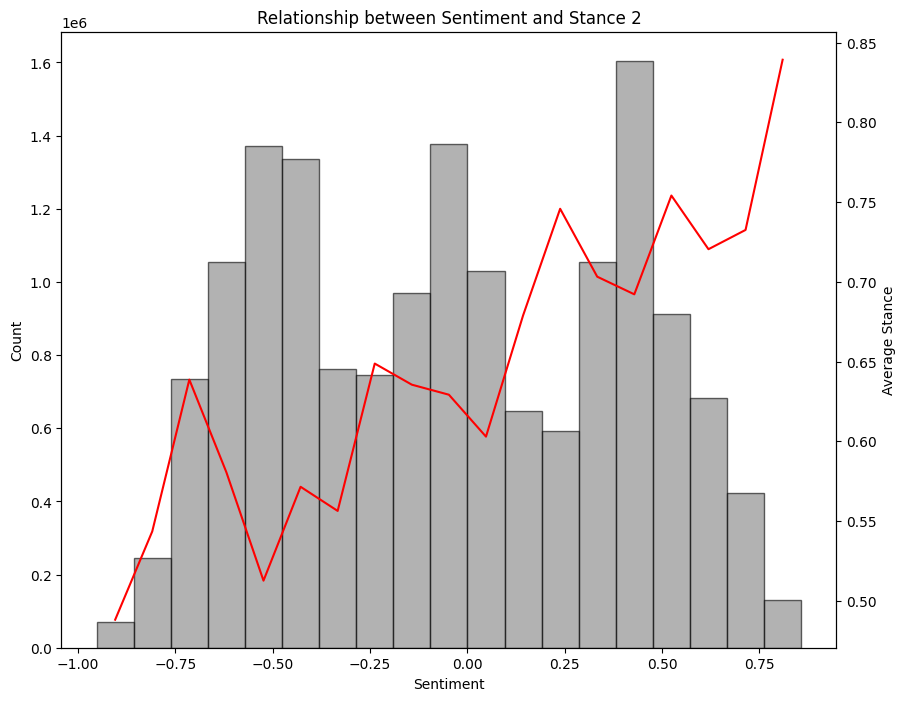

In [ ]:
# below I replicated a graph from one of the studies mentioned in my paper

bins = np.linspace(-1, 1, 22)
subset['sentiment_bin'] = pd.cut(subset['sentiment'], bins)

hist_ct, bin_edg = np.histogram(subset['sentiment'], bins)
mean_stance = subset.groupby('sentiment_bin')['stance_2'].mean()

fig, ax1 = plt.subplots(figsize = (10,8))

# since they found them to be outliers, they removed the first and last bins
hist_ct = hist_ct[1:-1]
bin_edg = bin_edg[1:-1]
mean_stance = mean_stance[1:-1]

# histogram: count (y) vs. sentiment bins (x)
ax1.bar(bin_edg[:-1], hist_ct, width = np.diff(bin_edg), color = 'grey', edgecolor = 'black', alpha = 0.6, label = 'Count')
ax1.set_xlabel('Sentiment')
ax1.set_ylabel('Count')
ax1.tick_params(axis = 'y', labelcolor = 'black')

# line plot: avg stance (y) vs. sentiment bins (x)
ax2 = ax1.twinx()
ax2.plot(bin_edg[:-1], mean_stance, color = 'red', label = 'Mean Stance')
ax2.set_ylabel('Average Stance')

plt.title('Relationship between Sentiment and Stance 2')
plt.show()

Again, we see the same correlation, the more positive a tweet is, the higher the average stance is, indicating that they are likely to believe in climate change. On the left hand side of the graph, we see that more negative tweets correlate with deniers.

In [ ]:
# since we have bins and continuous stance variable, I can use pearson correlation coefficient
corr, p_value = stats.pearsonr(bin_edg[:-1],mean_stance)
print(f"Correlation Coefficient: {corr}")
print(f"P-value: {p_value}")

Correlation Coefficient: 0.8926961777344006
P-value: 2.75032993153557e-07


There is around a 90% correlation between sentiment and average stance (which we knew from the study). The higher the sentiment, the higher the average stance.

Overall, through the various boxplots and line graphs, we can conclude that there is a correlation between positive sentiment  and climate change believers' tweets. When comparing my line graph (first one) with the study's (second one), we see a similar pattern, so my hypothesis was proven true.